# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 3 - Module 3
### **Practical 3: Basic Selection Methods in Genetic Algorithms**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module III: Genetic Algorithms and Evolutionary Computing |
| **Student Name** | *Aakash Sarang* |
| **Enrollment No.** | *2023BTCSE001* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To implement basic selection methods for selecting suitable individuals from a population using Python.

### 2. Theory: Selection Operators

Selection chooses parent chromosomes from the current population based on their fitness so that fitter individuals have a higher chance of reproducing:

1. **Roulette Wheel Selection (Fitness-Proportionate):** Probability $p_i = \frac{f_i}{\sum_j f_j}$.
2. **Tournament Selection:** Randomly picks $k$ individuals and selects the one with the highest fitness.
3. **Rank Selection:** Sorts individuals by fitness and assigns selection probabilities based on rank rather than raw fitness.

### 3. Step 1: Implementing Roulette Wheel, Tournament, and Rank Selection

In [1]:
import numpy as np

np.random.seed(42)

population = np.random.randint(0, 2, size=(8, 6))
fitness = np.array([np.sum(ind) for ind in population], dtype=float)
fitness = np.maximum(fitness, 1e-6)  # avoid zero-sum

def roulette_wheel_selection(pop, fit, num_select):
    probs = fit / np.sum(fit)
    indices = np.random.choice(len(pop), size=num_select, p=probs)
    return pop[indices], indices

def tournament_selection(pop, fit, num_select, k=3):
    selected_idx = []
    for _ in range(num_select):
        competitors = np.random.choice(len(pop), size=k, replace=False)
        winner = competitors[np.argmax(fit[competitors])]
        selected_idx.append(winner)
    return pop[selected_idx], np.array(selected_idx)

def rank_selection(pop, fit, num_select):
    ranks = np.argsort(np.argsort(fit)) + 1
    probs = ranks / np.sum(ranks)
    indices = np.random.choice(len(pop), size=num_select, p=probs)
    return pop[indices], indices

print("Population Fitness:", fitness)
_, r_idx = roulette_wheel_selection(population, fitness, 4)
_, t_idx = tournament_selection(population, fitness, 4, k=3)
_, rk_idx = rank_selection(population, fitness, 4)

print("Roulette Selected Indices:  ", r_idx)
print("Tournament Selected Indices:", t_idx)
print("Rank Selected Indices:      ", rk_idx)

Population Fitness: [2. 1. 3. 4. 6. 3. 1. 5.]
Roulette Selected Indices:   [4 6 2 4]
Tournament Selected Indices: [3 4 3 7]
Rank Selected Indices:       [2 6 4 2]


### 4. Step 2: Comparing Selection Pressure via Simulation

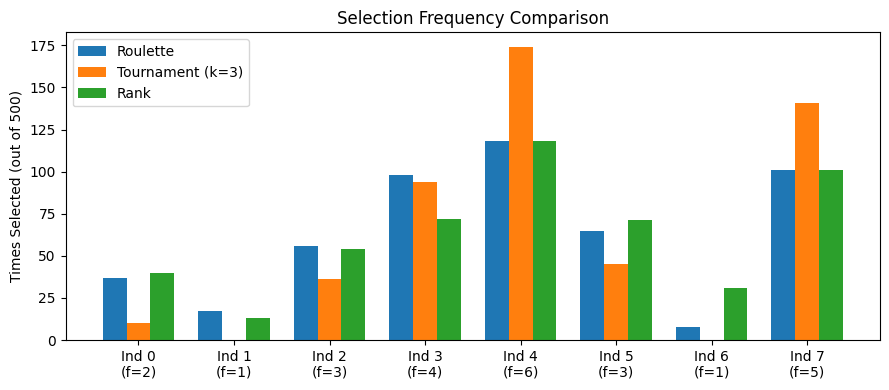

In [2]:
import matplotlib.pyplot as plt

trials = 500
_, r_all = roulette_wheel_selection(population, fitness, trials)
_, t_all = tournament_selection(population, fitness, trials, k=3)
_, rk_all = rank_selection(population, fitness, trials)

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(population))
w = 0.25
ax.bar(x - w, np.bincount(r_all, minlength=len(population)), width=w, label='Roulette')
ax.bar(x,     np.bincount(t_all, minlength=len(population)), width=w, label='Tournament (k=3)')
ax.bar(x + w, np.bincount(rk_all, minlength=len(population)), width=w, label='Rank')
ax.set_xticks(x)
ax.set_xticklabels([f"Ind {i}\n(f={int(fitness[i])})" for i in x])
ax.set_ylabel("Times Selected (out of 500)")
ax.set_title("Selection Frequency Comparison")
ax.legend()
plt.tight_layout()
plt.show()

### 5. Conclusion
We implemented Roulette Wheel, Tournament, and Rank selection and observed how tournament selection exerts stronger selection pressure toward fitter individuals.